# BIOT 6900 · Module 10 Assignment — Medical Imaging AI: Build It, Then Break It

Graded notebook (Notebook 3 of 3). Task: tumour vs. normal colon tissue (PathMNIST). I train a clean transfer-learned DenseNet121, probe it, design my own confounder, retrain, and test with a control whether the confounded model learned the shortcut.

**My confounder (Part C):** a *scanner/site label tag* in the top-left corner of every tumour tile (a white sticker with a barcode). It stands for data that "spills" in from a different source than the rest of the data: only one class carries the footprint of another site's scanner.

Pipeline adapted from Notebook 2. Runs on CPU.

## 0 · Setup

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as Fnn
import monai
from monai.utils import set_determinism
from monai.networks.nets import DenseNet121
from monai.visualize import GradCAM

SEED = 0
set_determinism(seed=SEED)
device = torch.device("cpu")      # laptop CPU run, as the assignment allows
print("MONAI:", monai.__version__, "| torch:", torch.__version__, "| device:", device)

MONAI: 1.6.1 | torch: 2.11.0 | device: cpu


## 1 · Data: PathMNIST, normal mucosa (0) vs. adenocarcinoma epithelium (1)

tiles are 64 px (resized to 128 px below)
train 600 (tumour 300) | val 400 (tumour 200) | test 600 (tumour 300)


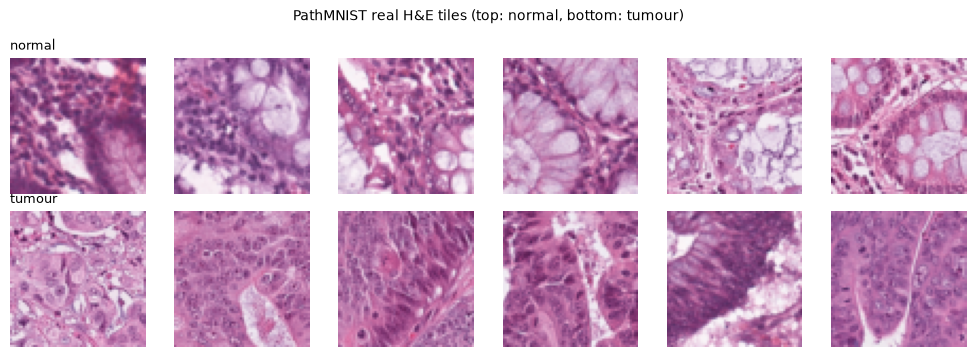

In [2]:
IMG_SIZE = 128
SUBSET_FILE = "./data/pathmnist_tumour_vs_normal_subset.npz"
class_names = ["normal", "tumour"]
assert os.path.exists(SUBSET_FILE), "put pathmnist_tumour_vs_normal_subset.npz in ./data/ (see build_subset.py)"
d = np.load(SUBSET_FILE)
xtr_s, ytr_s, xva_s, yva_s, xte_s, yte_s = (d[k] for k in ["xtr", "ytr", "xva", "yva", "xte", "yte"])
print(f"tiles are {xtr_s.shape[1]} px (resized to {IMG_SIZE} px below)")
print(f"train {len(ytr_s)} (tumour {int(ytr_s.sum())}) | val {len(yva_s)} (tumour {int(yva_s.sum())}) | test {len(yte_s)} (tumour {int(yte_s.sum())})")
fig, axes = plt.subplots(2, 6, figsize=(10, 3.6))
for r, c in enumerate((0, 1)):
    for k, j in enumerate(np.where(ytr_s == c)[0][:6]):
        axes[r, k].imshow(xtr_s[j]); axes[r, k].axis("off")
    axes[r, 0].set_title(class_names[c], fontsize=9, loc="left")
plt.suptitle("PathMNIST real H&E tiles (top: normal, bottom: tumour)", fontsize=10); plt.tight_layout(); plt.show()

## 2 · Preprocessing and Dataset (same as Notebook 2, plus a hook for my artifact)

In [3]:
from torch.utils.data import Dataset, DataLoader
from monai.transforms import Compose, EnsureChannelFirst, ScaleIntensity, Resize, EnsureType

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
to01 = Compose([EnsureChannelFirst(channel_dim=-1), ScaleIntensity(), Resize((IMG_SIZE, IMG_SIZE)), EnsureType(data_type="tensor")])
def normalize(x01): return (x01 - IMAGENET_MEAN) / IMAGENET_STD

add_artifact = None   # set in Part C

class TileDataset(Dataset):
    def __init__(self, imgs, labels, artifact_label=None):
        self.imgs, self.labels, self.artifact_label = imgs, labels, artifact_label
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        x01 = to01(self.imgs[i])
        if self.artifact_label is not None and self.labels[i] == self.artifact_label:
            x01 = add_artifact(x01)
        return normalize(x01), int(self.labels[i])

def make_loaders(artifact_label=None, bs=32):
    # an artifact (if any) goes into training AND validation tiles of that class
    g = torch.Generator().manual_seed(SEED)
    tr = DataLoader(TileDataset(xtr_s, ytr_s, artifact_label), batch_size=bs, shuffle=True, generator=g)
    va = DataLoader(TileDataset(xva_s, yva_s, artifact_label), batch_size=64)
    return tr, va

# PART A · Clean model (baseline and later the control)

In [4]:
def build_densenet(pretrained=True):
    return DenseNet121(spatial_dims=2, in_channels=3, out_channels=2, pretrained=pretrained).to(device)

TARGET_LAYER = "class_layers.relu"
def minmax_keep_high(x):
    flat = x.flatten(start_dim=1)
    lo = flat.min(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    hi = flat.max(dim=1)[0].view(-1, *([1] * (x.dim() - 1)))
    return (x - lo) / (hi - lo + 1e-8)
def make_cam(net): return GradCAM(nn_module=net, target_layers=TARGET_LAYER, postprocessing=minmax_keep_high)

def run_epoch(net, loader, opt=None):
    train_mode = opt is not None
    net.train() if train_mode else net.eval()
    crit = nn.CrossEntropyLoss(); tot = cor = 0; ls = 0.0
    with torch.set_grad_enabled(train_mode):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = net(x); loss = crit(out, y)
            if train_mode: opt.zero_grad(); loss.backward(); opt.step()
            ls += loss.item() * x.size(0); cor += (out.argmax(1) == y).sum().item(); tot += x.size(0)
    return ls / tot, cor / tot

def train(net, tr_loader, va_loader, epochs=3, lr=1e-4):
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    for ep in range(1, epochs + 1):
        _, tra = run_epoch(net, tr_loader, opt)
        _, vaa = run_epoch(net, va_loader)
        print(f"  epoch {ep}: train acc {tra:.3f} | val acc {vaa:.3f}")
    return net

EPOCHS = 3
set_determinism(seed=SEED)
tr_loader, va_loader = make_loaders()
print("Clean model (pretrained DenseNet121, fine-tuned):")
model = train(build_densenet(True), tr_loader, va_loader, epochs=EPOCHS)

Clean model (pretrained DenseNet121, fine-tuned):


  epoch 1: train acc 0.832 | val acc 0.958


  epoch 2: train acc 0.992 | val acc 0.968


  epoch 3: train acc 1.000 | val acc 0.960


CLEAN model | validation accuracy: 0.960 | test accuracy: 0.947


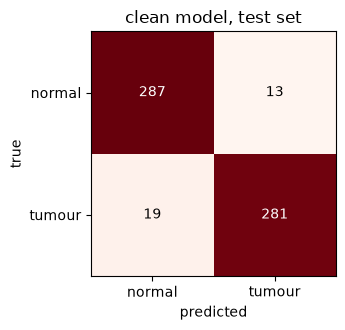

In [5]:
from sklearn.metrics import confusion_matrix
def evaluate(net, imgs, labels, artifact_label=None):
    net.eval(); preds = []
    for x, _ in DataLoader(TileDataset(imgs, labels, artifact_label), batch_size=64):
        with torch.no_grad(): preds.append(net(x.to(device)).argmax(1).cpu().numpy())
    preds = np.concatenate(preds)
    return preds, float((preds == labels).mean())

_, val_acc = evaluate(model, xva_s, yva_s)
pred, test_acc = evaluate(model, xte_s, yte_s)
print(f"CLEAN model | validation accuracy: {val_acc:.3f} | test accuracy: {test_acc:.3f}")
cm = confusion_matrix(yte_s, pred)
fig, ax = plt.subplots(figsize=(3.8, 3.4)); ax.imshow(cm, cmap="Reds")
ax.set_xticks([0,1]); ax.set_xticklabels(class_names); ax.set_yticks([0,1]); ax.set_yticklabels(class_names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(2):
    for j in range(2): ax.text(j, i, cm[i,j], ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else "black")
plt.title("clean model, test set"); plt.tight_layout(); plt.show()

# PART B · Probe the clean model (Grad-CAM + occlusion + checklist)

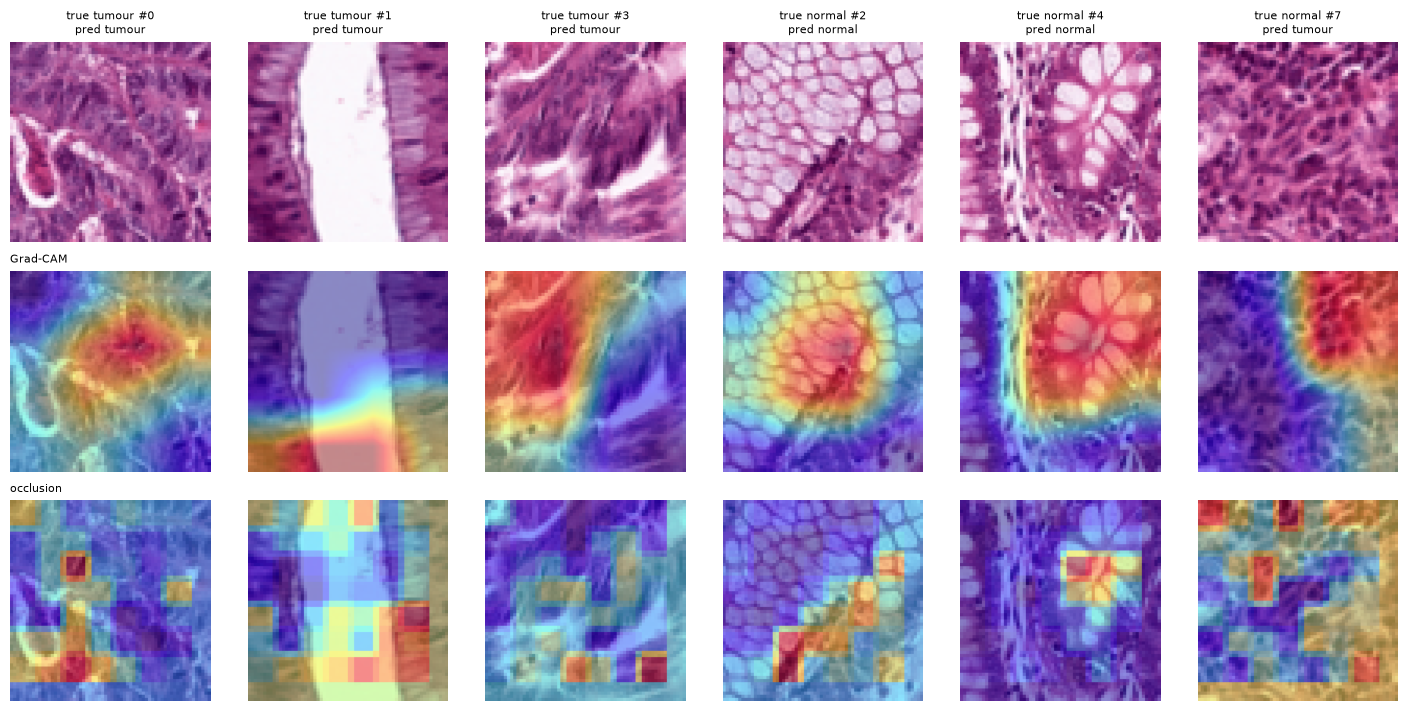

In [6]:
cam = make_cam(model)

def occlusion_map(net, x01, target, patch=20, stride=16, baseline=0.0):
    net.eval()
    xin = normalize(x01).unsqueeze(0).to(device)
    with torch.no_grad(): base = Fnn.softmax(net(xin), 1)[0, target].item()
    H = W = IMG_SIZE
    heat = np.zeros((H, W)); cnt = np.zeros((H, W))
    for i in range(0, H - patch + 1, stride):
        for j in range(0, W - patch + 1, stride):
            x2 = xin.clone(); x2[..., i:i+patch, j:j+patch] = baseline
            with torch.no_grad(): p = Fnn.softmax(net(x2), 1)[0, target].item()
            heat[i:i+patch, j:j+patch] += (base - p); cnt[i:i+patch, j:j+patch] += 1
    return heat / np.maximum(cnt, 1)

def show_maps(net, cam_obj, tiles, titles):
    k = len(tiles)
    fig, ax = plt.subplots(3, k, figsize=(2.4*max(k,2), 7.2), squeeze=False)
    for col, (x01, t) in enumerate(zip(tiles, titles)):
        xin = normalize(x01).unsqueeze(0).to(device)
        pr = int(net(xin).argmax(1).item())
        g = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
        o = occlusion_map(net, x01, pr)
        disp = x01.permute(1,2,0).cpu().numpy()
        ax[0,col].imshow(disp); ax[0,col].set_title(f"{t}\npred {class_names[pr]}", fontsize=8)
        ax[1,col].imshow(disp); ax[1,col].imshow(g, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[2,col].imshow(disp); ax[2,col].imshow(o, cmap="jet", alpha=0.45)
        for r in range(3): ax[r,col].axis("off")
    ax[1,0].set_title("Grad-CAM", fontsize=8, loc="left"); ax[2,0].set_title("occlusion", fontsize=8, loc="left")
    plt.tight_layout(); plt.show()

tum = np.where(yte_s == 1)[0][:3]; nor = np.where(yte_s == 0)[0][:3]
tiles  = [to01(xte_s[j]) for j in list(tum) + list(nor)]
titles = [f"true tumour #{j}" for j in tum] + [f"true normal #{j}" for j in nor]
show_maps(model, cam, tiles, titles)

**Part B · Five-point skeptic's checklist on the clean model**

*Result:* the clean model got 96.0% on validation and 94.7% on test (the test images come from a different centre).

1. In the Grad-CAM maps the red areas are mostly on nuclei and gland shapes in 5 of the 6 tiles. In one tumour tile the red area runs along a white empty space, and one normal tile was called tumour.
2. The occlusion maps are blocky and match Grad-CAM only partly.
3. I did not test a different target class, stain or scanner.
4. Six tiles are only an example, so I cannot be sure.

*My answer:* the clean model mostly looks at tissue. The clean control in part D is the real test.

# PART C · My own confounder: a scanner/site label tag on tumour tiles
**Why it is a plausible real-world batch effect.** In real slide archives, tiles are cut from whole-slide images that carry the footprint of the scanner and the lab: label stickers, barcodes, corner text, annotation boxes. If the tumour slides in a collection were scanned or labelled at one site and the normal slides at another, then "tag in the corner" correlates with the diagnosis and says nothing about the tissue. A model can pick that up. It is also the kind of artifact a clean model should mostly ignore: it is small, sits at the edge, and is unlike anything in the pretrained features.

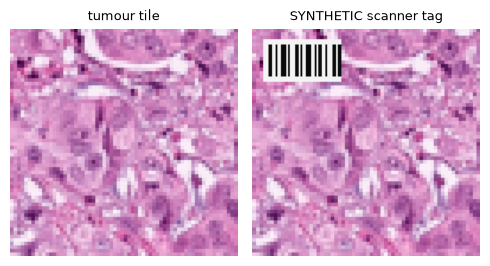

the tag covers 6.4% of the tile


In [7]:
ARTIFACT_LABEL = 1                # the tag goes onto tumour tiles only
TAG_ROWS, TAG_COLS = (6, 30), (6, 50)     # top-left corner, about 6% of the tile
TAG_MASK = torch.zeros(IMG_SIZE, IMG_SIZE, dtype=torch.bool)
TAG_MASK[TAG_ROWS[0]:TAG_ROWS[1], TAG_COLS[0]:TAG_COLS[1]] = True

# barcode pattern (fixed): alternating dark bars of different widths on a white sticker
_bars = torch.ones(TAG_ROWS[1]-TAG_ROWS[0], TAG_COLS[1]-TAG_COLS[0])
_c = 3
for w, gap in [(2,2),(1,2),(3,1),(1,3),(2,1),(1,2),(3,2),(1,1),(2,2),(1,3),(2,1),(3,1),(1,2)]:
    _bars[3:-3, _c:_c+w] = 0.0; _c += w + gap
TAG_PIXELS = _bars.clamp(0, 1) * 0.92 + 0.04      # off-white sticker, near-black bars

def add_tag(x01):
    out = x01.clone()
    out[:, TAG_ROWS[0]:TAG_ROWS[1], TAG_COLS[0]:TAG_COLS[1]] = TAG_PIXELS.unsqueeze(0).expand(3, -1, -1)
    return out
add_artifact = add_tag

j = int(np.where(ytr_s == 1)[0][0]); clean_t = to01(xtr_s[j])
fig, ax = plt.subplots(1, 2, figsize=(5, 2.7))
ax[0].imshow(clean_t.permute(1,2,0).numpy()); ax[0].set_title("tumour tile", fontsize=9)
ax[1].imshow(add_tag(clean_t).permute(1,2,0).numpy()); ax[1].set_title("SYNTHETIC scanner tag", fontsize=9)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print(f"the tag covers {TAG_MASK.float().mean():.1%} of the tile")

In [8]:
# retrain the SAME setup; every tumour tile (train and validation) now carries the tag
set_determinism(seed=SEED)
tr_cf, va_cf = make_loaders(artifact_label=ARTIFACT_LABEL)
print("Confounded model (tumour tiles carry the tag):")
model_cf = train(build_densenet(True), tr_cf, va_cf, epochs=EPOCHS)
_, test_acc_cf_tagged = evaluate(model_cf, xte_s, yte_s, artifact_label=ARTIFACT_LABEL)
print(f"confounded model, test accuracy when the test set carries the same tag on tumour tiles: {test_acc_cf_tagged:.3f}")

Confounded model (tumour tiles carry the tag):


  epoch 1: train acc 0.895 | val acc 0.995


  epoch 2: train acc 1.000 | val acc 1.000


  epoch 3: train acc 1.000 | val acc 1.000


confounded model, test accuracy when the test set carries the same tag on tumour tiles: 1.000


# PART D · Did the model learn the tag? The full battery, with the clean control

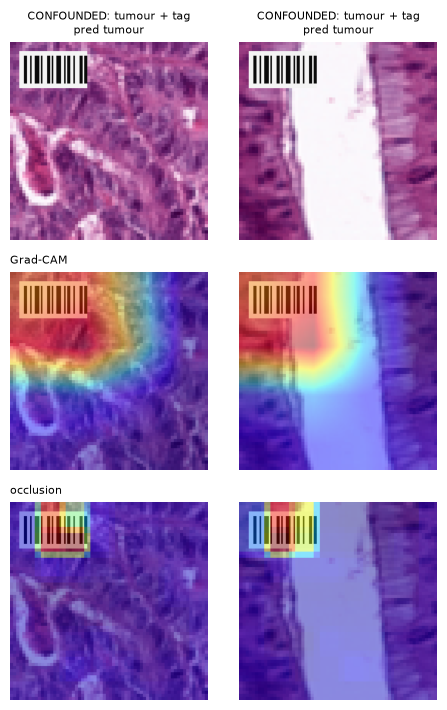

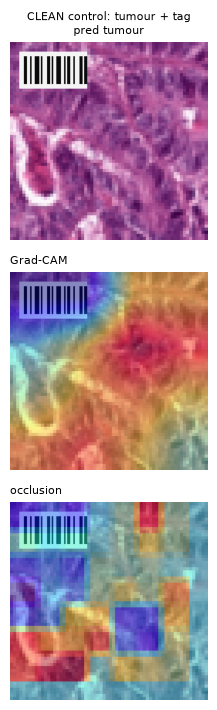

tag covers 6.4% of the tile; mean share of evidence on the tag over 8 tagged tumour tiles:
  confounded     Grad-CAM 16% | occlusion 63%
  clean control  Grad-CAM 2% | occlusion 10%


In [9]:
cam_cf = make_cam(model_cf)
jt = int(np.where(yte_s == 1)[0][0]); jn = int(np.where(yte_s == 0)[0][0])
# (1) maps on a tagged tumour tile, for the confounded model AND the clean control
show_maps(model_cf, cam_cf, [add_tag(to01(xte_s[jt])), add_tag(to01(xte_s[int(np.where(yte_s==1)[0][1])]))], ["CONFOUNDED: tumour + tag", "CONFOUNDED: tumour + tag"])
show_maps(model,    cam,    [add_tag(to01(xte_s[jt]))], ["CLEAN control: tumour + tag"])

def share_on_tag(m):
    m = np.clip(m, 0, None)
    return float(m[TAG_MASK.numpy()].sum() / (m.sum() + 1e-8))
def tag_shares(net, cam_obj, x01):
    xin = normalize(x01).unsqueeze(0).to(device)
    pr = int(net(xin).argmax(1).item())
    g = cam_obj(x=xin, class_idx=pr).squeeze().detach().cpu().numpy()
    return share_on_tag(g), share_on_tag(occlusion_map(net, x01, pr))
tum_idx = np.where(yte_s == 1)[0][:8]
rows = []
for name, net, co in [("confounded", model_cf, cam_cf), ("clean control", model, cam)]:
    s = np.array([tag_shares(net, co, add_tag(to01(xte_s[j]))) for j in tum_idx])
    rows.append((name, s[:,0].mean(), s[:,1].mean()))
print(f"tag covers {TAG_MASK.float().mean():.1%} of the tile; mean share of evidence on the tag over {len(tum_idx)} tagged tumour tiles:")
for name, g, o in rows: print(f"  {name:14s} Grad-CAM {g:.0%} | occlusion {o:.0%}")

In [10]:
# (2) Reliance test: tumour recall WITH the tag vs WITHOUT it
def predict_tiles(net, idxs, transform=None):
    net.eval(); out = []
    with torch.no_grad():
        for j in idxs:
            x01 = to01(xte_s[j])
            if transform is not None: x01 = transform(x01)
            out.append(int(net(normalize(x01).unsqueeze(0).to(device)).argmax(1).item()))
    return np.array(out)
ti = np.where(yte_s == 1)[0]; ni = np.where(yte_s == 0)[0]
res = {}
for name, net in [("confounded", model_cf), ("clean control", model)]:
    res[name] = dict(
        recall_with=float((predict_tiles(net, ti, add_tag) == 1).mean()),
        recall_without=float((predict_tiles(net, ti) == 1).mean()),
        flip=float((predict_tiles(net, ni, add_tag) == 1).mean()),
        normal_ok=float((predict_tiles(net, ni) == 0).mean()))
print(f"{'':14s} {'tumour recall':>26s} {'normal tiles + tag':>20s}")
print(f"{'':14s} {'with tag':>12s} {'without tag':>13s} {'called tumour (flip)':>22s}")
for name, r in res.items():
    print(f"{name:14s} {r['recall_with']:12.1%} {r['recall_without']:13.1%} {r['flip']:22.1%}")
print()
print("(2) reliance : a big drop from 'with tag' to 'without tag' means the model leaned on the tag.")
print("(3) flip rate: share of NORMAL test tiles that become 'tumour' once the tag is added.")
print("(4) control  : the clean model never saw the tag. The gap between the rows is the proof.")

                            tumour recall   normal tiles + tag
                   with tag   without tag   called tumour (flip)
confounded           100.0%         37.0%                  96.7%
clean control         99.0%         93.7%                  23.0%

(2) reliance : a big drop from 'with tag' to 'without tag' means the model leaned on the tag.
(3) flip rate: share of NORMAL test tiles that become 'tumour' once the tag is added.
(4) control  : the clean model never saw the tag. The gap between the rows is the proof.


**Part D · Reading the numbers**

1. Without the tag, the confounded model's tumour recall fell from 100.0% to 37.0%. The clean control's fell from 99.0% to 93.7%.
2. With the tag added to normal tiles, the confounded model called 96.7% tumour. The clean control called 23.0% tumour.
3. With the tag moved to the wrong class, the confounded model scored 20.2% (chance is 50%).
4. In the confounded model, 16% of the Grad-CAM evidence and 63% of the occlusion evidence is on the tag, which covers 6.4% of the tile. In the clean control the numbers are 2% and 10%.
5. The clean control is not completely unmoved (23.0% flips). The tag may be a little easy to notice because I added it after resizing. I did not test this.

*My answer:* yes, the confounded model learned the tag. The clean control reacted much less, and the gap is far bigger than the noise of about 2 to 3 points with 300 tiles per class. This used one seed and a made-up tag.

## Optional extra check: is the tag the only shortcut? (train/validation leakage check)
Since the tag was injected into validation as well, validation accuracy cannot tell us about it. This check scores the confounded model on a test set where the tag is placed on the **wrong** class (on normal tiles instead of tumour tiles). If the model relies on the tag, accuracy on that set should fall far below 50%.

In [11]:
swap_pred = []
model_cf.eval()
with torch.no_grad():
    for j in range(len(yte_s)):
        x01 = to01(xte_s[j])
        if yte_s[j] == 0: x01 = add_tag(x01)          # tag on normal, none on tumour
        swap_pred.append(int(model_cf(normalize(x01).unsqueeze(0).to(device)).argmax(1).item()))
swap_acc = float((np.array(swap_pred) == yte_s).mean())
print(f"confounded model, tag moved to the wrong class: accuracy {swap_acc:.1%} (chance = 50%)")

confounded model, tag moved to the wrong class: accuracy 20.2% (chance = 50%)


# PART E · Report
The 3 to 4 page report is in this folder: `Module 10 report.docx`.
